In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.10 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3132
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


SEED = 3132. The split and the folds use it, and so does every random model.

In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]   # members of voting and stacking in Parts 3-4

The models are defined once here and not changed later. When I fit one more than once I use `clone`.

## Part 1 — Bagging and out-of-bag estimates

In [4]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [5]:
print(oob_mask([0, 2, 2], 5))
print(oob_mask([], 3))
print(oob_mask(np.array([3, 0]), 4))

[False  True False  True  True]
[ True  True  True]
[False  True  True False]


In [6]:
bag.fit(X_train, y_train)
n = len(y_train)

oob_share = np.mean([oob_mask(s, n).mean() for s in bag.estimators_samples_])
print(f"mean OOB share:      {oob_share:.4f}")
print(f"mean in-bag share:   {1 - oob_share:.4f}")
print(f"(1 - 1/n)^n:         {(1 - 1/n) ** n:.4f}")
print(f"1 - (1 - 1/n)^n:     {1 - (1 - 1/n) ** n:.4f}")

mean OOB share:      0.3683
mean in-bag share:   0.6317
(1 - 1/n)^n:         0.3678
1 - (1 - 1/n)^n:     0.6322


In [7]:
votes = np.zeros((n, 2), dtype=int)
for est, samples in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(samples, n)
    pred = est.predict(X_train[mask])
    votes[np.where(mask)[0], pred] += 1

oob_pred = votes.argmax(axis=1)      # tie goes to class 0
my_oob_acc = (oob_pred == y_train).mean()
print(f"my OOB accuracy:  {my_oob_acc:.4f}")
print(f"bag.oob_score_:   {bag.oob_score_:.4f}")

my OOB accuracy:  0.9369
bag.oob_score_:   0.9369


On average a tree misses 36.8% of the training rows (OOB) and sees 63.2% of them. The formula (1 - 1/n)^n gives 36.8% too, so the bootstrap behaves as expected: each tree has about a third of the rows that it never saw.

My own OOB accuracy is 0.9369 and `bag.oob_score_` is 0.9369. They are the same, so my vote counting does what scikit-learn does.

In [8]:
from sklearn.model_selection import cross_validate

models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
scores = {name: cross_validate(m, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
          for name, m in models.items()}

table = pd.DataFrame(scores).T
table.columns = [f"fold {i+1}" for i in range(5)]
table["mean"] = table.iloc[:, :5].mean(axis=1)
table["std"] = table.iloc[:, :5].std(axis=1, ddof=0)
table.round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.9002,0.9017,0.8859,0.9079,0.9048,0.9001,0.0076
bag,0.9334,0.9287,0.9350,0.9302,0.9524,0.9359,0.0085
rf,0.9366,0.9477,0.9572,0.9492,0.9556,0.9493,0.0073
lr,0.9382,0.9382,0.9303,0.9365,0.9492,0.9385,0.0061
bag_lr,0.9382,0.9414,0.9303,0.9349,0.9524,0.9394,0.0074


In [9]:
def paired(a, b):
    d = scores[a] - scores[b]
    verdict = "inside spread" if abs(d.mean()) <= d.std() else "outside spread"
    print(f"{a} - {b}: {np.round(d, 4)}  mean={d.mean():.4f}  std={d.std():.4f}  -> {verdict}")

paired("bag", "tree")
paired("rf", "tree")
paired("bag_lr", "lr")

bag - tree: [0.0333 0.0269 0.0491 0.0222 0.0476]  mean=0.0358  std=0.0108  -> outside spread
rf - tree: [0.0365 0.046  0.0713 0.0413 0.0508]  mean=0.0492  std=0.0121  -> outside spread
bag_lr - lr: [ 0.      0.0032  0.     -0.0016  0.0032]  mean=0.0010  std=0.0019  -> inside spread


In [10]:
rf.fit(X_train, y_train)
p = rf.score(X_test, y_test)
se = np.sqrt(p * (1 - p) / len(y_test))

print(f"rf oob_score_:        {rf.oob_score_:.4f}")
print(f"rf CV mean:           {scores['rf'].mean():.4f}  (fold std {scores['rf'].std():.4f})")
print(f"rf test accuracy:     {p:.4f}  (standard error {se:.4f})")
print(f"|oob - CV mean|:      {abs(rf.oob_score_ - scores['rf'].mean()):.4f}")

rf oob_score_:        0.9477
rf CV mean:           0.9493  (fold std 0.0073)
rf test accuracy:     0.9420  (standard error 0.0072)
|oob - CV mean|:      0.0016


**(a) Does bagging help?**
For the tree, yes. Bagging raised the CV accuracy from 0.900 to 0.936, and the gain is positive on all five folds (mean +0.036, std 0.011), so it is clearly larger than the fold spread. A single deep tree has high variance: it memorises the training rows. Averaging 100 trees trained on different bootstrap samples smooths that out.
For logistic regression, no. The change is +0.001 with std 0.002, which is inside the spread, so my data cannot tell it apart from zero. Logistic regression is stable: a bootstrap sample gives almost the same model, so there is little variance for bagging to remove.

**(b) Is OOB a fair stand-in for CV?**
Yes. The forest's `oob_score_` is 0.9477 and its CV mean is 0.9493. The difference, 0.0016, is much smaller than the fold std of 0.0073, so they agree. The test accuracy is 0.9420 with a standard error of 0.0072. It is a little lower than both, but the gap is about one standard error, so all three numbers tell the same story.

## Part 2 — Evaluating the filter

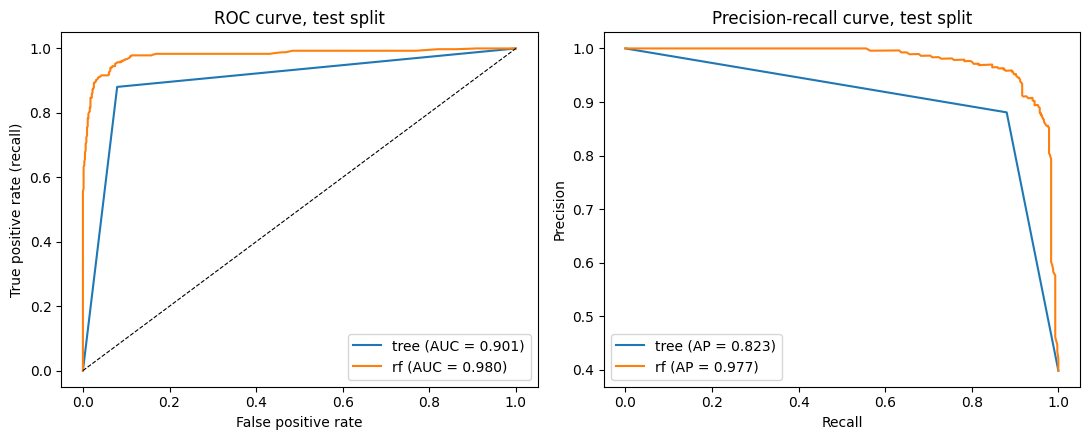

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)

tree.fit(X_train, y_train)
score = {"tree": tree.predict_proba(X_test)[:, 1], "rf": rf.predict_proba(X_test)[:, 1]}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, s in score.items():
    fpr_, tpr_, _ = roc_curve(y_test, s)
    ax[0].plot(fpr_, tpr_, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
    prec_, rec_, _ = precision_recall_curve(y_test, s)
    ax[1].plot(rec_, prec_, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve, test split")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve, test split")
ax[0].legend(loc="lower right")
ax[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, thr = roc_curve(y_train, oof, drop_intermediate=False)

allowed = fpr <= 0.01                           # out-of-fold FPR at most 1 %
best_recall = tpr[allowed].max()
candidates = np.where(allowed & (tpr == best_recall))[0]
i = candidates[np.argmax(thr[candidates])]      # several thresholds -> take the largest
t = thr[i]

print(f"t = {t:.4f}   out-of-fold FPR = {fpr[i]:.4f}   out-of-fold recall = {tpr[i]:.4f}")

t = 0.7233   out-of-fold FPR = 0.0095   out-of-fold recall = 0.8210


In [13]:
pred = (score["rf"] >= t).astype(int)
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()

print(pd.DataFrame(cm, index=["true legit", "true spam"], columns=["pred legit", "pred spam"]))
print(f"precision = {tp / (tp + fp):.4f}")
print(f"recall    = {tp / (tp + fn):.4f}")
print(f"FPR       = {fp / (fp + tn):.4f}")
print(f"legitimate test mails flagged: {fp} of {fp + tn}")

            pred legit  pred spam
true legit         621         11
true spam           73        346
precision = 0.9692
recall    = 0.8258
FPR       = 0.0174
legitimate test mails flagged: 11 of 632


The forest is much better than the single tree: AUC 0.980 against 0.901, average precision 0.977 against 0.823. Its curve stays high and close to the corner, the tree's does not.

I chose the threshold on out-of-fold probabilities of the training split only. The best recall with FPR at most 1% is reached at t = 0.7233, where the out-of-fold FPR is 0.0095 and the recall is 0.821.

On the test split with this t: 11 of 632 legitimate mails were flagged, so FPR = 0.0174, precision = 0.969, recall = 0.826.

**Did the 1% target hold? No.** The test FPR is 1.74%, above 1%. With 632 legitimate mails, 1% means about 6 mails, and I got 11. Part of this is plain noise, since a few mails move the rate a lot on a sample this small. The out-of-fold models also saw only 80% of the training rows, so their probabilities are a bit different from the final forest's. The threshold itself was chosen honestly and I did not change it after seeing the test result.

In [14]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
imp = pd.DataFrame({"feature": feature_names,
                    "permutation": perm.importances_mean,
                    "impurity": rf.feature_importances_})

print("Top 5 by permutation importance (test split)")
display(imp.sort_values("permutation", ascending=False).head(5)[["feature", "permutation"]].round(4))
print("Top 5 by impurity importance (training split)")
display(imp.sort_values("impurity", ascending=False).head(5)[["feature", "impurity"]].round(4))

Top 5 by permutation importance (test split)


,feature,permutation
6,word_freq_remove,0.0414
51,char_freq_exclam,0.0166
52,char_freq_dollar,0.0123
54,capital_run_length_average,0.0101
24,word_freq_hp,0.0099


Top 5 by impurity importance (training split)


,feature,impurity
51,char_freq_exclam,0.1232
52,char_freq_dollar,0.0908
6,word_freq_remove,0.0825
15,word_freq_free,0.0732
20,word_freq_your,0.0690


In [15]:
imp["rank_permutation"] = imp["permutation"].rank(ascending=False).astype(int)
imp["rank_impurity"] = imp["impurity"].rank(ascending=False).astype(int)
imp[imp["feature"] == "word_freq_free"].round(4)

,feature,permutation,impurity,rank_permutation,rank_impurity
15,word_freq_free,0.0043,0.0732,11,4


**Did the 1% target hold on the test split?** No. 11 of 632 legitimate test mails were flagged, so the FPR is 1.74%.

**Importances.** Both lists agree on the main features: `char_freq_exclam`, `char_freq_dollar` and `word_freq_remove` are in the top three of both. The order differs, though. `word_freq_remove` is first by permutation (0.041) and third by impurity (0.083).

Take `word_freq_free`. It is 4th by impurity (0.073) but only 11th by permutation (0.004). The two numbers measure different things. Impurity importance is the total drop in impurity over all splits that use the feature, counted on the **training** rows. A deep tree keeps splitting on "free" even for small gains that only fit the training data, and 300 trees add all of that up. Permutation importance shuffles the feature on the **test** mails and measures how much the accuracy falls. If other spam words (`remove`, `your`, `money`, `!`) carry a similar signal, the forest still gets those mails right without "free", so the accuracy hardly drops. So "free" is used a lot by the trees, but it is not something the filter would miss on new mail.

## Part 3 — Voting

In [16]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    preds = np.array(predictions, dtype=int)          # a copy, the argument stays untouched
    n_models, n_samples = preds.shape
    if n_samples == 0:
        return np.zeros(0, dtype=int)
    w = np.ones(n_models) if weights is None else np.array(weights, dtype=float)

    n_labels = int(preds.max()) + 1
    counts = np.zeros((n_labels, n_samples))
    cols = np.arange(n_samples)
    for m in range(n_models):                         # model 0 first, so the sums are in model order
        counts[preds[m], cols] += w[m]
    return np.argmax(counts, axis=0).astype(int)      # argmax takes the first maximum: the smallest label

In [17]:
print(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]))
print(hard_vote([[0, 1], [1, 0]]))
print(hard_vote([[0, 1], [1, 0]], weights=[1, 2]))
print(hard_vote([[2, 0], [2, 1], [0, 1]]))

[0 1 0]
[0 0]
[1 0]
[2 1]


In [18]:
import itertools
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

member_preds = np.array([clone(m).fit(X_train, y_train).predict(X_test) for _, m in members])
sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print(f"agreement with VotingClassifier: {(hard_vote(member_preds) == sk_hard).mean():.4f}")

names = [n for n, _ in members]
rows = [{"pair": f"{names[i]} vs {names[j]}", "disagree": (member_preds[i] != member_preds[j]).mean()}
        for i, j in itertools.combinations(range(3), 2)]
pd.DataFrame(rows).round(4)

agreement with VotingClassifier: 1.0000


,pair,disagree
0,lr vs knn,0.0533
1,lr vs tree,0.0847
2,knn vs tree,0.1132


In [20]:
vote_hard = VotingClassifier(members, voting="hard")
vote_soft = VotingClassifier(members, voting="soft")
cands = {"lr": lr, "knn": knn, "tree": tree, "hard": vote_hard, "soft": vote_soft}
vscores = {k: cross_validate(m, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
           for k, m in cands.items()}

vtable = pd.DataFrame(vscores).T
vtable.columns = [f"fold {i+1}" for i in range(5)]
vtable["mean"] = vtable.iloc[:, :5].mean(axis=1)
vtable["std"] = vtable.iloc[:, :5].std(axis=1, ddof=0)
display(vtable.round(4))

best = max(["lr", "knn", "tree"], key=lambda k: vscores[k].mean())
print("best member:", best)
for k in ["hard", "soft"]:
    d = vscores[k] - vscores[best]
    verdict = "inside spread" if abs(d.mean()) <= d.std() else "outside spread"
    print(f"{k} - {best}: {np.round(d, 4)}  mean={d.mean():.4f}  std={d.std():.4f}  -> {verdict}")

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.9382,0.9382,0.9303,0.9365,0.9492,0.9385,0.0061
knn,0.9176,0.9065,0.9271,0.9048,0.9286,0.9169,0.0100
tree,0.9002,0.9017,0.8859,0.9079,0.9048,0.9001,0.0076
hard,0.9366,0.9398,0.9398,0.9333,0.9540,0.9407,0.0071
soft,0.9366,0.9398,0.9429,0.9286,0.9444,0.9385,0.0056


best member: lr
hard - lr: [-0.0016  0.0016  0.0095 -0.0032  0.0048]  mean=0.0022  std=0.0046  -> inside spread
soft - lr: [-0.0016  0.0016  0.0127 -0.0079 -0.0048]  mean=-0.0000  std=0.0071  -> inside spread


My `hard_vote` gives the same labels as `VotingClassifier(voting="hard")` on 100% of the test rows.

The members do disagree: lr and knn differ on 5.3% of the test mails, lr and tree on 8.5%, knn and tree on 11.3%. So there is something to combine.

The best member by cross-validation is logistic regression (0.9385).

**Hard voting:** mean 0.9407, which is +0.0022 against logistic regression, with std 0.0046. The difference is inside the fold spread, so my data cannot separate the two. I do not call hard voting a winner.

**Soft voting:** mean 0.9385, the paired difference is 0.0000 with std 0.0071. Also inside the spread, so again no winner.

Why no gain? The members are different, but two of the three are clearly weaker than logistic regression: knn is at 0.917 and the single tree at 0.900. They fix some of its mistakes and bring their own, and the two effects cancel out.